# 28 · A larger, more diverse set of pairs

Notebooks 22 to 27 train on notebook 21's pairs: the host's two lines (x264 and NVENC), labelled with what the client
reads off each frame - the slice QP, the loop filter, I or P. The labels and the QP bins are what the client needs. The
content is narrow:

- **YouTube video only.** Notebook 17 measured one sequence of each training video and two of each test video, and
  kept 394 that are cheap to code and detailed at the finest scale (306 train, 88 validation). There are about five
  sequences of each video on disk.
- **No screens and no photos**, though a desktop stream is mostly screens. Notebook 8 found screens were the data the
  upscaler was missing (+0.019 SSIM-Y on screens).
- **8 patches a frame**, so one frame gives a fifth of a target's patches.

This notebook makes the set again with the same lines, bins, labels and patch shape, and wider content:

- **Video**: every sequence of every video measured with notebook 17's test (median QP under 18 at 0.26 bpp, x1, and a
  bicubic round trip of 44 dB or less), and up to `VIDEO_CLIPS_PER_VIDEO` of those that pass from each video, spread
  over it.
- **Screens**: the desktop screens `datasets/screens.py` draws: its first set (400 train, 80 validation) and a second one
  drawn from other seeds (`screens-s1`, 600 and 120). Each becomes a 32-frame clip at 30 fps of a 1920×1080 or 1280×720
  window sliding, zooming or standing still over it (`helpers/motion.py`, as notebook 0 does).
- **Photos**: DIV2K (train for training, valid for validation) and Flickr2K (training only), the same way.
- **4 patches a frame**: the same frames per bin from many more sources, each spot half as likely to repeat a neighbour.
- **A `kind` label** per patch (video, screen, photo). It is for scoring by kind, never for training.

The split stays by source: a video's sequences are all on its side of YouTube-8M's split, a screen's split is the one
it was drawn for (with DIV2K train or valid photos in it), and DIV2K keeps its own.

It writes `qp_diverse_pairs/` in the format of `qp_slice_pairs/`, so notebooks 22 to 27 read it by changing
`PAIRS_DIR`. Notebook 21's set stays as it is.

**Limits.** As in notebook 21: NVENC reads frames swscale shrank with bicubic, where the host's NVENC line shrinks on
the GPU. The screens are drawn, and a still image moved by whole pixels is not every motion a desktop makes.

Needs: notebook 17, part 5's measurements (`qp/qp_targets.csv`, reused), `uv run datasets/screens.py --seed 1 --name
screens-s1 --train 600 --test 120`, and an NVIDIA GPU with NVENC. Writes `qp/qp_targets_all.csv` and `qp_diverse_pairs/`.

In [1]:
"""Settings."""

import json
import os
import re
import shutil
import time
import zlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from threading import BoundedSemaphore

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

os.environ["DATASETS_DIR"] = "/mnt/d/datasets"   # where the datasets are: set before helpers is imported

from helpers import degrade, metrics, models, motion, patches, sources
from helpers.training import DEVICE

OLD_TARGETS_FILE = sources.ROOT / "upscale" / "qp" / "qp_targets.csv"   # notebook 17, part 5: reused, not measured again
TARGETS_FILE = sources.ROOT / "upscale" / "qp" / "qp_targets_all.csv"   # every sequence, measured here
PAIRS_DIR = sources.ROOT / "upscale" / "qp_diverse_pairs"
PARTS_DIR = PAIRS_DIR / "_parts"        # one file a source while the set is made, so a run resumes; removed at the end

# the sources
SIZES = ((1920, 1080), (1280, 720))     # a clip's size before the x2: a video's largest it fills, an image's at random
CLIP_FRAMES, SETTLE = 32, 8
VIDEO_CLIPS_PER_VIDEO = 3               # targets a video at most, spread over it (notebook 21: 1 train, 2 test)
REFERENCE_BPP, SCORE_EVERY = 0.26, 10   # notebook 17's test of a video target...
TARGET_MAX_QP, TARGET_MAX_ROUND_TRIP_DB = 18, 44   # ...and its limits
IMAGES = {                              # files a split, None for all; "val" reads a dataset's test.txt
    "screens": {"train": None, "val": None},      # datasets/screens.py
    "screens-s1": {"train": None, "val": None},   # datasets/screens.py --seed 1 --name screens-s1
    "div2k": {"train": 250, "val": 60},
    "flickr2k": {"train": 150},
}
IMAGE_FPS = 30
KINDS = ("video", "screen", "photo")
MEASURE_WORKERS = 8

# the pairs: notebook 21's lines, bins and labels
SCALE = 2
PAIR_MBPS = (0.25, 0.5, 1, 2, 4, 8)            # streams to find frames of each QP bin in
QP_EDGES = (0, 18, 26, 30, 34, 38, 42, 46, 52)   # bins of the slice QP
FRAMES_PER_BIN, INTRA_FRAMES = 1, 1            # a source and encoder: P frames in each bin, I frames in all
PATCHES_PER_FRAME, PATCH_HR, HALO = 4, 128, 4  # notebook 21: 8 a frame
VAR_MIN, MIN_LR_PSNR = 24.0, 22.0              # skip flat spots, and spots with nothing of the target left
WORKERS, NVENC_AT_ONCE = 12, 6                 # the 3090's driver (621) runs 8 NVENC sessions at once: leave two

LUMA = np.array([0.2126, 0.7152, 0.0722], np.float32)
PARTS_DIR.mkdir(parents=True, exist_ok=True)
print("datasets", sources.ROOT, " device", DEVICE)

datasets /mnt/d/datasets  device cuda


## 1. Video targets

Every sequence of every video, measured as notebook 17 measured its targets: x264 at `REFERENCE_BPP` and x1, the median
QP of its settled P frames (low: cheap to code, so clean), and the frames halved and restored with bicubic (low:
detail at the finest scale). Notebook 17's measurements are reused; the rest are cached in `TARGETS_FILE` a batch at a
time (a clip too small or too short gets an empty row). Of the sequences of a video that pass, up to
`VIDEO_CLIPS_PER_VIDEO`, spread over it. YouTube-8M's test videos are validation.

In [2]:
MIX = Path(sources.__file__).resolve().parents[3] / "datasets" / "yt8m-mix.txt"


def video_groups():
    """Category folder -> its group, from the sections of the mix file (notebook 17)."""
    major = minor = None
    groups = {}
    for line in MIX.read_text(encoding="utf-8").splitlines():
        if heading := re.match(r"# == (\w+)", line):
            major = heading[1]
        elif heading := re.match(r"# -- (.+?) - [\d.]+", line):
            minor = heading[1]
        elif entry := re.match(r"[\d.]+\s+(.+?)\s*$", line):
            folder = re.sub(r"[^\w-]+", "_", entry[1]).strip("_")
            groups[folder] = "camera footage" if major == "Other" else minor.lower()
    return groups


def frames_of(path):
    """A sequence's first `CLIP_FRAMES` frames, centre-cropped to the largest of `SIZES` it fills, and its frame rate."""
    frames, fps = sources.load_sequence(path)
    frames = frames[:CLIP_FRAMES]
    size = next((s for s in SIZES if frames.shape[2] >= s[0] and frames.shape[1] >= s[1]), None)
    if size is None or len(frames) < CLIP_FRAMES:
        return None, fps
    top, left = (frames.shape[1] - size[1]) // 4 * 2, (frames.shape[2] - size[0]) // 4 * 2
    return frames[:, top:top + size[1], left:left + size[0]], fps


def round_trip_db(frames):
    """Luma PSNR of frames halved and restored with bicubic, the median: high means soft (notebook 17)."""
    luma = torch.from_numpy(frames[SETTLE::SCORE_EVERY].astype(np.float32) @ LUMA)[:, None]
    back = F.interpolate(F.interpolate(luma, scale_factor=0.5, mode="area"), size=luma.shape[2:], mode="bicubic", align_corners=False)
    mse = ((back - luma) ** 2).mean((1, 2, 3)).clamp(min=1e-6)
    return float((10 * torch.log10(255 ** 2 / mse)).median())


def target_row(clip):
    """A sequence's median QP at `REFERENCE_BPP`, x1, and its round trip in dB; empty if it is too small or short."""
    frames, fps = frames_of(clip["path"])
    if frames is None:
        return {"key": clip["key"], "reference_qp": np.nan, "round_trip_db": np.nan}
    made = degrade.Degradation(scale=1, bpp=REFERENCE_BPP, fps=fps, filter="bicubic", deblock=False)
    (report, _), = degrade.encode_reports(frames, [made])
    qp = np.median([row["qp"] for row in report if row["type"] == "P" and row["frame"] >= SETTLE])
    return {"key": clip["key"], "reference_qp": float(qp), "round_trip_db": round_trip_db(frames)}


groups = video_groups()
sequences = []
for split, listing in (("train", "train"), ("val", "test")):
    for path in sources.files("yt8m-videos", listing):
        category, video = path.parts[-3:-1]
        sequences.append({"key": f"yt8m-videos/{video}/{path.stem}", "dataset": "yt8m-videos", "kind": "video",
                          "category": category, "group": groups.get(category, "other"), "video": video,
                          "split": split, "path": path})

if not TARGETS_FILE.exists():
    shutil.copyfile(OLD_TARGETS_FILE, TARGETS_FILE)
measured_keys = set(pd.read_csv(TARGETS_FILE)["key"])
todo = [clip for clip in sequences if clip["key"] not in measured_keys]
print(f"{len(sequences)} sequences of {len({c['video'] for c in sequences})} videos; {len(measured_keys)} measured, {len(todo)} to measure")
start = time.time()
with ThreadPoolExecutor(MEASURE_WORKERS) as pool:
    for first in range(0, len(todo), 200):
        rows = list(pool.map(target_row, todo[first:first + 200]))
        pd.DataFrame(rows).to_csv(TARGETS_FILE, mode="a", header=False, index=False)
        print(f"  {first + len(rows)} of {len(todo)}, {time.time() - start:.0f} s")

measured = pd.read_csv(TARGETS_FILE).drop_duplicates("key").set_index("key")
passes = set(measured.index[(measured["reference_qp"] < TARGET_MAX_QP) & (measured["round_trip_db"] <= TARGET_MAX_ROUND_TRIP_DB)])
by_video = {}
for clip in sequences:
    if clip["key"] in passes:
        by_video.setdefault(clip["video"], []).append(clip)
video_targets = []
for video, clips in sorted(by_video.items()):
    clips = sorted(clips, key=lambda c: c["key"])
    step = max(1, len(clips) // VIDEO_CLIPS_PER_VIDEO)
    video_targets += clips[step // 2::step][:VIDEO_CLIPS_PER_VIDEO]

table = pd.DataFrame([{**c, "passes": c["key"] in passes} for c in sequences])
table["target"] = table["key"].isin({c["key"] for c in video_targets})
print(f"\n{len(passes)} of {len(measured)} measured sequences pass; {len(video_targets)} targets "
      f"({sum(c['split'] == 'train' for c in video_targets)} train, {sum(c['split'] == 'val' for c in video_targets)} validation) "
      f"from {len({c['video'] for c in video_targets})} videos")
print(table.groupby(["group"]).agg(sequences=("key", "size"), videos=("video", "nunique"), pass_=("passes", "sum"),
                                   targets=("target", "sum"), videos_used=("video", lambda v: v[table.loc[v.index, "target"]].nunique()))
      .rename(columns={"pass_": "pass"}).to_string())

5000 sequences of 1000 videos; 5000 measured, 0 to measure

1840 of 5000 measured sequences pass; 1396 targets (1227 train, 169 validation) from 612 videos
                            sequences  videos  pass  targets  videos_used
group                                                                    
2d, retro and casual games        150      30    51       40           17
animation                         500     100   206      158           68
camera footage                   1000     200   244      193           89
console and general games         350      70   103       90           46
creative software                 250      50   139       94           34
desktop and software use          750     150   469      313          114
live action                       600     120   193      168           85
music and live                    400      80    53       45           27
pc games                          750     150   301      230          102
phones and tablets            

## 2. Screens and photos

Every drawn screen of both sets, and a sample of the photos. Each is turned into a clip when its pairs are made: a
window of one of `SIZES` that fits the picture, at random, sliding, zooming or standing still over it
(`motion.sample`), drawn from the source's own seed. A screen's category is how it was drawn: a `page` (one
application on a tall canvas) or a `desktop` (a whole screen).

In [3]:
pick = np.random.default_rng(0)
image_sources = []
for dataset, wanted in IMAGES.items():
    kind = "screen" if dataset.startswith("screens") else "photo"
    drawn = {}
    if kind == "screen":
        drawn = {row["file"]: row["kind"] for row in json.loads((sources.RAW / dataset / "screens.json").read_text(encoding="utf-8"))}
    for split, count in wanted.items():
        paths = sources.files(dataset, "test" if split == "val" else "train")
        if count is not None and count < len(paths):
            paths = [paths[i] for i in sorted(pick.choice(len(paths), count, replace=False))]
        for path in paths:
            name = path.relative_to(sources.RAW / dataset).as_posix()
            image_sources.append({"key": f"{dataset}/{name}", "dataset": dataset, "kind": kind,
                                  "category": drawn.get(name, dataset), "split": split, "path": path})

everything = video_targets + image_sources
counts = pd.DataFrame([{"kind": s["kind"], "dataset": s["dataset"], "content": s.get("group", s["category"]), "split": s["split"]}
                       for s in everything])
print(counts.pivot_table(index=["kind", "dataset", "content"], columns="split", aggfunc="size", fill_value=0).to_string())
print(f"\n{len(everything)} sources")

split                                          train  val
kind   dataset     content                               
photo  div2k       div2k                         250   60
       flickr2k    flickr2k                      150    0
screen screens     desktop                       186   29
                   page                          214   51
       screens-s1  desktop                       245   38
                   page                          355   82
video  yt8m-videos 2d, retro and casual games     34    6
                   animation                     138   20
                   camera footage                166   27
                   console and general games      79   11
                   creative software              79   15
                   desktop and software use      276   37
                   live action                   153   15
                   music and live                 40    5
                   pc games                      203   27
              

## 3. Pairs

Notebook 21's recipe for each source: for each encoder, the clip through the host's line at x2 at every bitrate of
`PAIR_MBPS` with the slice header report on each frame; then `FRAMES_PER_BIN` settled P frames of each slice QP bin and
`INTRA_FRAMES` I frames, from whichever stream gave them; and `PATCHES_PER_FRAME` patches of each, not flat and not
destroyed. The streams are made by `degrade.degrade_many`: notebook 21's ffmpeg commands, reading and writing files in
memory rather than pipes, which held the GIL so long that eight threads ran slower than one. One source's patches are
written to `PARTS_DIR` when it is done, so a stopped run picks up where it was.

In [4]:
PATCH_LR = PATCH_HR // SCALE
INPUT_LR = PATCH_LR + 2 * HALO
QP_BINS = list(zip(QP_EDGES[:-1], QP_EDGES[1:]))
DTYPES = {"qp": np.float32, "mean_qp": np.float32, "deblocked": np.bool_, "intra": np.bool_, "encoder": np.int8, "kind": np.int8}
nvenc_sessions = BoundedSemaphore(NVENC_AT_ONCE)


def clip_of(source, rng):
    """A source's frames, their rate, and how an image was shown (None for a video, or for an image too small)."""
    if source["kind"] == "video":
        frames, fps = frames_of(source["path"])
        return frames, fps, None
    image = sources.load_image(source["path"])
    height, width = image.shape[:2]
    fits = [size for size in SIZES if width >= size[0] and height >= size[1]]
    if not fits:
        return None, IMAGE_FPS, None
    shown = motion.sample(rng, (width, height), CLIP_FRAMES, fits[int(rng.integers(len(fits)))])
    return motion.render(image, shown), IMAGE_FPS, shown


def lr_psnr(lr_core, hr_patch):
    """Luma PSNR of a stream spot against a clean downscale of its target."""
    clean = (hr_patch.astype(np.float32) @ LUMA).reshape(PATCH_LR, SCALE, PATCH_LR, SCALE).mean(axis=(1, 3))
    mse = ((lr_core.astype(np.float32) @ LUMA - clean) ** 2).mean()
    return 10 * np.log10(255 ** 2 / max(mse, 1e-10))


def spots(hr, lr, rng):
    """Up to `PATCHES_PER_FRAME` (LR with its halo, HR) of one frame, not flat and not destroyed."""
    out = []
    for _ in range(4 * PATCHES_PER_FRAME):
        if len(out) == PATCHES_PER_FRAME:
            break
        y, x = (2 * int(rng.integers(0, (size - INPUT_LR) // 2 + 1)) for size in lr.shape[:2])   # even pixels: 4:2:0
        y_hr, x_hr = (y + HALO) * SCALE, (x + HALO) * SCALE
        hr_patch, lr_patch = hr[y_hr:y_hr + PATCH_HR, x_hr:x_hr + PATCH_HR], lr[y:y + INPUT_LR, x:x + INPUT_LR]
        if (hr_patch.astype(np.float32) @ LUMA).var() >= VAR_MIN and lr_psnr(lr_patch[HALO:-HALO, HALO:-HALO], hr_patch) >= MIN_LR_PSNR:
            out.append((lr_patch.copy(), hr_patch.copy()))
    return out


def streams_of(frames, fps, encoder):
    """{mbps: (Degradation, LR, report)} of one encoder at every bitrate of `PAIR_MBPS`."""
    lr_width, lr_height = degrade.stream_size(*degrade.crop(frames, SCALE).shape[2:0:-1], SCALE)
    made = [degrade.Degradation(scale=SCALE, bpp=mbps * 1e6 / (lr_width * lr_height * fps), fps=fps,
                                filter="bicubic", deblock=False, encoder=encoder) for mbps in PAIR_MBPS]
    if encoder == "nvenc":
        with nvenc_sessions:
            streams = degrade.degrade_many(frames, made)
    else:
        streams = degrade.degrade_many(frames, made)
    return {mbps: (d, lr, report) for mbps, d, (lr, _, report) in zip(PAIR_MBPS, made, streams)}


def part_path(source):
    return PARTS_DIR / (source["key"].replace("/", "__") + ".npz")


def make_part(source):
    """Write one source's patches and labels to its part file; return None, or what went wrong."""
    path = part_path(source)
    if path.exists():
        return None
    try:
        rng = np.random.default_rng(zlib.crc32(source["key"].encode()))
        frames, fps, shown = clip_of(source, rng)
        out = {"lr": [], "hr": [], **{name: [] for name in DTYPES}}
        entries = []
        hr = degrade.crop(frames, SCALE) if frames is not None else None
        for e, encoder in enumerate(degrade.ENCODERS if frames is not None else ()):
            streams = streams_of(frames, fps, encoder)
            found = {qp_bin: [] for qp_bin in QP_BINS} | {"intra": []}
            for mbps, (_, _, report) in streams.items():
                for row in report:
                    if row["type"] == "I":
                        found["intra"].append((mbps, row))
                    elif row["frame"] >= SETTLE:
                        for low, high in QP_BINS:
                            if low <= row["slice_qp"] < high:
                                found[low, high].append((mbps, row))
            chosen = {}
            for key, candidates in found.items():
                keep = INTRA_FRAMES if key == "intra" else FRAMES_PER_BIN
                for i in rng.permutation(len(candidates))[:keep]:
                    mbps, row = candidates[i]
                    chosen.setdefault(mbps, []).append(row)
            for mbps, rows in sorted(chosen.items()):
                made, lr, _ = streams[mbps]
                first = len(out["lr"])
                for row in rows:
                    for lr_patch, hr_patch in spots(hr[row["frame"]], lr[row["frame"]], rng):
                        out["lr"].append(lr_patch)
                        out["hr"].append(hr_patch)
                        out["qp"].append(row["slice_qp"])
                        out["mean_qp"].append(row.get("qp", np.nan))
                        out["deblocked"].append(row["deblocked"])
                        out["intra"].append(row["type"] == "I")
                        out["encoder"].append(e)
                        out["kind"].append(KINDS.index(source["kind"]))
                if len(out["lr"]) > first:
                    entries.append({"key": source["key"], "dataset": source["dataset"], "kind": source["kind"],
                                    "category": source["category"], "mbps": mbps, "encoder": encoder,
                                    "patches": [first, len(out["lr"])], "degradation": made.as_dict(),
                                    **({"motion": shown.as_dict()} if shown is not None else {})})
            del streams
        arrays = {"lr": np.array(out["lr"], np.uint8).reshape(-1, INPUT_LR, INPUT_LR, 3),
                  "hr": np.array(out["hr"], np.uint8).reshape(-1, PATCH_HR, PATCH_HR, 3),
                  **{name: np.array(out[name], dtype) for name, dtype in DTYPES.items()}}
        partial = path.with_name(path.name + ".tmp")
        with open(partial, "wb") as file:
            np.savez(file, **arrays, sources=np.array(json.dumps(entries)))
        os.replace(partial, path)   # a part is whole or not there
        return None
    except Exception as error:   # one bad source is reported, not the end of the run
        return f"{source['key']}: {error}"


todo = [s for s in everything if not part_path(s).exists()]
print(f"{len(everything) - len(todo)} sources done before, {len(todo)} to do")
start, failed = time.time(), []
with ThreadPoolExecutor(WORKERS) as pool:
    for done, error in enumerate(pool.map(make_part, todo), 1):
        if error:
            failed.append(error)
        if done % 250 == 0 or done == len(todo):
            print(f"  {done} of {len(todo)}, {time.time() - start:.0f} s")
print(f"{len(failed)} failed" + "".join(f"\n  {line}" for line in failed[:20]))

0 sources done before, 3056 to do
  250 of 3056, 325 s
  500 of 3056, 635 s
  750 of 3056, 937 s
  1000 of 3056, 1263 s
  1250 of 3056, 1583 s
  1500 of 3056, 1916 s
  1750 of 3056, 2262 s
  2000 of 3056, 2604 s
  2250 of 3056, 2958 s
  2500 of 3056, 3305 s
  2750 of 3056, 3616 s
  3000 of 3056, 3920 s
  3056 of 3056, 3980 s
0 failed


The parts, in the order of `everything`, become one array a field and split, written straight to disk: the training
split is several GB, more than is worth holding twice in memory. Then the manifest, and the parts go.

In [5]:
def write_npy(file, dtype, shape):
    """Open `file` as an .npy of this dtype and shape whose data is then written in order."""
    out = open(file, "wb")
    np.lib.format.write_array_header_1_0(out, {"descr": np.dtype(dtype).str, "fortran_order": False, "shape": shape})
    return out


if failed:
    raise RuntimeError(f"{len(failed)} sources failed - run the cell above again")
splits = {}
for split in ("train", "val"):
    members = [s for s in everything if s["split"] == split]
    sizes = []
    for source in members:
        with np.load(part_path(source)) as part:
            sizes.append(len(part["kind"]))
    total = sum(sizes)
    lr_file = write_npy(PAIRS_DIR / f"{split}_lr.npy", np.uint8, (total, 1, INPUT_LR, INPUT_LR, 3))   # (patches, 1 frame, h, w, 3)
    hr_file = write_npy(PAIRS_DIR / f"{split}_hr.npy", np.uint8, (total, 1, PATCH_HR, PATCH_HR, 3))
    labels, entries, at = {name: [] for name in DTYPES}, [], 0
    for source, size in zip(members, sizes):
        with np.load(part_path(source)) as part:
            lr_file.write(np.ascontiguousarray(part["lr"]).tobytes())
            hr_file.write(np.ascontiguousarray(part["hr"]).tobytes())
            for name in DTYPES:
                labels[name].append(part[name])
            entries += [{**entry, "patches": [entry["patches"][0] + at, entry["patches"][1] + at]}
                        for entry in json.loads(str(part["sources"]))]
        at += size
    lr_file.close()
    hr_file.close()
    for name, dtype in DTYPES.items():
        np.save(PAIRS_DIR / f"{split}_{name}.npy", np.concatenate(labels[name]).astype(dtype))
    splits[split] = {"patches": total, "lr": f"{split}_lr.npy", "hr": f"{split}_hr.npy",
                     **{name: f"{split}_{name}.npy" for name in DTYPES}, "sources": entries}
    print(f"{split:<6}{total:7} patches from {len({e['key'] for e in entries})} of {len(members)} sources")

manifest = {"scale": SCALE, "patch_lr": PATCH_LR, "patch_hr": PATCH_HR, "halo": HALO, "input_lr": INPUT_LR,
            "frames_per_patch": 1, "encoders": list(degrade.ENCODERS), "kinds": list(KINDS), "splits": splits}
(PAIRS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=1), encoding="utf-8")
shutil.rmtree(PARTS_DIR)
written = sum(p.stat().st_size for p in PAIRS_DIR.glob("*.npy"))
print(f"{written / 1e9:.1f} GB written to {PAIRS_DIR}")

train  147813 patches from 2603 of 2627 sources
val     24216 patches from 426 of 429 sources
11.1 GB written to /mnt/d/datasets/upscale/qp_diverse_pairs


## 4. Checks

What the set holds by kind, against notebook 21's; and bicubic against the target by kind and slice QP bin, P frames,
which must get worse as the QP rises within every kind, or the label means nothing. Then a few pairs, to see that LR and
HR show the same spot.

In [6]:
manifest = json.loads((PAIRS_DIR / "manifest.json").read_text(encoding="utf-8"))
labels = {split: {name: np.load(PAIRS_DIR / manifest["splits"][split][name]) for name in DTYPES} for split in ("train", "val")}
old = json.loads((sources.ROOT / "upscale" / "qp_slice_pairs" / "manifest.json").read_text(encoding="utf-8"))

rows = []
for split in ("train", "val"):
    lab = labels[split]
    for k, kind in enumerate(KINDS):
        mine = lab["kind"] == k
        rows.append({"split": split, "kind": kind, "patches": int(mine.sum()), "share": f"{mine.mean():.0%}",
                     "sources": len({e["key"] for e in manifest["splits"][split]["sources"] if e["kind"] == kind}),
                     "NVENC": f"{(lab['encoder'][mine] == 1).mean():.0%}", "I frames": f"{lab['intra'][mine].mean():.0%}",
                     "slice QP 38+": f"{(lab['qp'][mine] >= 38).mean():.0%}"})
    rows.append({"split": split, "kind": "notebook 21", "patches": old["splits"][split]["patches"],
                 "sources": len({e["key"] for e in old["splits"][split]["sources"]})})
print(pd.DataFrame(rows).fillna("").to_string(index=False))

for split in ("train", "val"):
    lab = labels[split]
    bins = pd.cut(lab["qp"], QP_EDGES, right=False, labels=[f"{a}-{b}" for a, b in QP_BINS])
    print(f"\n{split} patches by slice QP bin, P and I frames")
    print(pd.crosstab([np.array(KINDS)[lab["kind"]], np.array(manifest["encoders"])[lab["encoder"]]], bins,
                      rownames=["kind", "encoder"], colnames=["slice QP"]).to_string())

split        kind  patches share  sources NVENC I frames slice QP 38+
train       video    68537   46%     1227   50%      14%          20%
train      screen    55255   37%      984   51%      13%          26%
train       photo    24021   16%      392   52%      13%          30%
train notebook 21    34364            306                            
  val       video     9424   39%      169   49%      14%          19%
  val      screen    11142   46%      197   52%      13%          26%
  val       photo     3650   15%       60   53%      13%          30%
  val notebook 21     9628             88                            

train patches by slice QP bin, P and I frames
slice QP        0-18  18-26  26-30  30-34  34-38  38-42  42-46  46-52
kind   encoder                                                       
photo  nvenc    1743   1857   1814   1696   1907   1557   1308    714
       x264     1102   1619   1642   1728   1785   1622   1196    731
screen nvenc    4313   4495   4182   4085  

In [7]:
val_lr, val_hr = patches.load(PAIRS_DIR, "val", manifest)
val = labels["val"]


def to_tensor(images):
    return torch.from_numpy(np.array(images)).to(DEVICE).permute(0, 3, 1, 2).float() / 255


@torch.no_grad()
def bicubic_ssim(members):
    """Mean SSIM-Y of bicubic on these validation patches."""
    out = [metrics.per_image(patches.trim(models.bicubic(to_tensor(val_lr[batch]), SCALE), HALO * SCALE),
                             to_tensor(val_hr[batch]))["ssim"].cpu() for batch in np.array_split(members, max(1, len(members) // 256))]
    return float(torch.cat(out).mean())


rows = []
for k, kind in enumerate(KINDS):
    for e, encoder in enumerate(manifest["encoders"]):
        row = {"kind": kind, "encoder": encoder}
        for low, high in QP_BINS:
            members = np.flatnonzero((val["kind"] == k) & (val["encoder"] == e) & ~val["intra"] & (val["qp"] >= low) & (val["qp"] < high))
            row[f"{low}-{high}"] = round(bicubic_ssim(members), 4) if len(members) >= 20 else None
        members = np.flatnonzero((val["kind"] == k) & (val["encoder"] == e) & val["intra"])
        row["I frames"] = round(bicubic_ssim(members), 4)
        rows.append(row)
print("bicubic SSIM-Y against the target, validation P frames by slice QP bin (blank: under 20 patches)")
print(pd.DataFrame(rows).fillna("").to_string(index=False))
print(f"\nall validation patches: {bicubic_ssim(np.arange(len(val_lr))):.4f}; "
      + ", ".join(f"{kind} {bicubic_ssim(np.flatnonzero(val['kind'] == k)):.4f}" for k, kind in enumerate(KINDS)))

bicubic SSIM-Y against the target, validation P frames by slice QP bin (blank: under 20 patches)
  kind encoder   0-18  18-26  26-30  30-34  34-38  38-42  42-46  46-52  I frames
 video    x264 0.9614 0.9356 0.9128 0.8797 0.8576 0.8310 0.8006 0.7827    0.8764
 video   nvenc 0.9603 0.9466 0.9299 0.9192 0.8955 0.8655 0.8439 0.8438    0.9226
screen    x264 0.9041 0.8842 0.8696 0.8459 0.8212 0.7943 0.7923 0.8040    0.8296
screen   nvenc 0.8977 0.8928 0.8842 0.8674 0.8460 0.8074 0.7894 0.7561    0.8436
 photo    x264 0.8710 0.8353 0.7781 0.7230 0.6624 0.6015 0.5912 0.6347    0.6692
 photo   nvenc 0.8680 0.8475 0.8087 0.7726 0.7124 0.6767 0.6349 0.6012    0.7090

all validation patches: 0.8524; video 0.9034, screen 0.8487, photo 0.7322


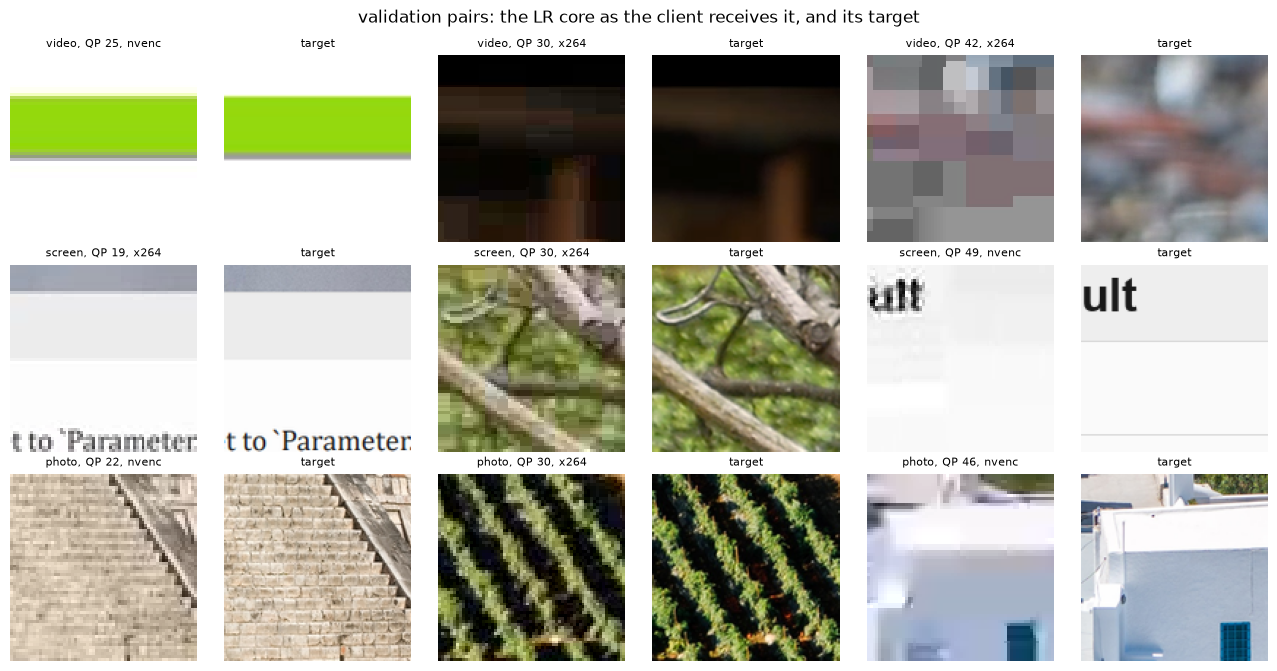

In [8]:
show = np.random.default_rng(1)
fig, axes = plt.subplots(len(KINDS), 6, figsize=(13, 6.8))
for k, kind in enumerate(KINDS):
    for column, (low, high) in enumerate(((0, 26), (30, 38), (42, 52))):
        members = np.flatnonzero((val["kind"] == k) & (val["qp"] >= low) & (val["qp"] < high))
        if not len(members):
            continue
        i = int(show.choice(members))
        axes[k, 2 * column].imshow(val_lr[i][HALO:-HALO, HALO:-HALO], interpolation="nearest")
        axes[k, 2 * column].set_title(f"{kind}, QP {val['qp'][i]:.0f}, {manifest['encoders'][val['encoder'][i]]}", fontsize=8)
        axes[k, 2 * column + 1].imshow(val_hr[i])
        axes[k, 2 * column + 1].set_title("target", fontsize=8)
for axis in axes.flat:
    axis.set_axis_off()
fig.suptitle("validation pairs: the LR core as the client receives it, and its target")
plt.tight_layout()
plt.show()

## 5. What it says

**147,813 training and 24,216 validation patches, 4.3 and 2.5 times notebook 21's**, from 2,603 and 426 sources (306
and 88 there), 11.1 GB. In training 46% are video, 37% screens and 16% photos; in validation 39%, 46% and 15%. Each
kind is half x264 and half NVENC, and about one patch in seven is from an I frame, as in notebook 21. 16 training
screens, 8 photos and 3 validation screens gave no patch.

**Video**: 1,840 of the 5,000 sequences pass notebook 17's test. 1,396 are targets, up to three a video: 1,227 from 540
training videos and 169 from 72 validation videos, where notebook 21 had 306 from 306 and 88 from 54. Every group of the
mix is in both splits.

**The top bins fill.** Slice QP 42 and up: 17,732 training patches against notebook 21's 3,190. NVENC's P frames at
46-52, which notebook 21 found thin: 2,630 against 430 in training, 422 against 64 in validation. Screens and photos
reach those bins far more than the video does: notebook 17 picked videos that are cheap to code, and a detailed picture
sliding at 0.25 Mbit/s is not.

**Bicubic against the target, validation: 0.8524 SSIM-Y**; video 0.9034 (notebook 21's set, all video, reads 0.9045),
screens 0.8487, photos 0.7322. The set is harder by its content, so **a score on it is not comparable with one on
notebook 21's set**: compare models on one set.

Within every kind and line, bicubic falls as the slice QP rises, up to 42-46: the label still means what it did. From
18-26 to 38-42, NVENC's frames are closer to the target than x264's at the same QP in every kind, as notebook 21 found on
video. At 46-52, x264's screens and photos score above their 42-46 bin; the likely reason is `MIN_LR_PSNR`, which drops
the spots the codec destroyed and keeps the easier ones.

**Time:** 14 minutes to measure 3,977 sequences, 66 minutes for the pairs with 12 sources at once, 1.5 minutes to
assemble. The streams go through `degrade.degrade_many`: with notebook 21's `degrade` in threads, 12 sources took 156 s
on 8 threads, slower than one at a time.

**Next:** train notebook 22's told 24×2 on this set (its `PAIRS_DIR`), and score it and notebook 23's shipped graph on
both sets, by kind.